# 타이타닉 생존 데이터 분석

인터넷에서 타이타닉 승객 데이터를 내려받아 결측치를 정리한 뒤, 성별·객실 등급·연령대·가족 동반 여부에 따른 생존율을 분석합니다.

**데이터 출처:** [Seaborn Titanic dataset](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv)

필요한 라이브러리가 없다면 먼저 다음 명령을 실행하세요: `pip install pandas matplotlib`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

# 그래프의 한글 표시 설정(Windows 기준)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 불러오기 및 원본 확인

중복 행은 승객 식별자 없이 실제 중복 승객인지 판단할 수 없으므로 삭제하지 않습니다.

In [2]:
df = pd.read_csv(DATA_URL)

required_columns = {
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"데이터에 필요한 컬럼이 없습니다: {sorted(missing_columns)}")

print("원본 데이터 크기:", df.shape)
print("\n원본 결측치 개수:")
display(df.isnull().sum().to_frame("결측치 개수"))
print(f"완전히 같은 행의 개수: {df.duplicated().sum()}")

원본 데이터 크기: (891, 15)

원본 결측치 개수:


,결측치 개수
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


완전히 같은 행의 개수: 107


## 2. 데이터 클렌징 및 파생 변수 생성

- 나이는 성별·객실 등급별 중앙값으로 채우고, 남은 결측치는 전체 중앙값으로 채웁니다.
- 승선 항구는 최빈값, 요금은 중앙값으로 채웁니다.
- 결측치가 많은 `deck`과 중복 의미의 파생 컬럼을 제외합니다.
- 가족 수와 연령대 변수를 새로 만듭니다.

In [3]:
age_medians = df.groupby(["sex", "pclass"])["age"].transform("median")
df["age"] = df["age"].fillna(age_medians).fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode().iloc[0])
df["fare"] = df["fare"].fillna(df["fare"].median())

df = df.drop(
    columns=["deck", "class", "who", "adult_male", "embark_town", "alive", "alone"],
    errors="ignore",
)
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["alone"] = df["family_size"] == 1
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 13, 20, 36, 61, float("inf")],
    labels=["12세 이하", "13~19세", "20~35세", "36~60세", "61세 이상"],
    right=False,
)

print("정제 후 데이터 크기:", df.shape)
print("\n정제 후 결측치 개수:")
display(df.isnull().sum().to_frame("결측치 개수"))
display(df.head())

정제 후 데이터 크기: (891, 11)

정제 후 결측치 개수:


,결측치 개수
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
family_size,0
alone,0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,family_size,alone,age_group
0,0,3,male,22.0,1,0,7.2500,S,2,False,20~35세
1,1,1,female,38.0,1,0,71.2833,C,2,False,36~60세
2,1,3,female,26.0,0,0,7.9250,S,1,True,20~35세
3,1,1,female,35.0,1,0,53.1000,S,2,False,20~35세
4,0,3,male,35.0,0,0,8.0500,S,1,True,20~35세


## 3. 여러 기준으로 생존율 분석

생존 여부는 `survived` 컬럼에서 1(생존), 0(사망)으로 표시됩니다. 평균을 구하면 생존율이 됩니다.

In [4]:
print(f"전체 승객 수: {len(df)}명")
print(f"전체 생존율: {df['survived'].mean():.1%}")

analysis_groups = [
    ("sex", "성별 생존 현황"),
    ("pclass", "객실 등급별 생존 현황"),
    ("age_group", "연령대별 생존 현황"),
    ("embarked", "승선 항구별 생존 현황"),
    ("alone", "혼자 탑승 여부별 생존 현황"),
]

for column, title in analysis_groups:
    summary = (
        df.groupby(column, observed=True)["survived"]
        .agg(승객수="size", 생존자수="sum", 생존율="mean")
    )
    summary["생존율"] = summary["생존율"].map("{:.1%}".format)
    print(f"\n{title}")
    display(summary)

fare_summary = df.groupby("survived")["fare"].agg(["count", "mean", "median"])
fare_summary.index = ["사망", "생존"]
fare_summary.columns = ["승객수", "평균 요금", "중앙값 요금"]
print("생존 여부별 요금 통계")
display(fare_summary.round(2))

전체 승객 수: 891명
전체 생존율: 38.4%

성별 생존 현황


,승객수,생존자수,생존율
sex,,,
female,314,233,74.2%
male,577,109,18.9%



객실 등급별 생존 현황


,승객수,생존자수,생존율
pclass,,,
1,216,136,63.0%
2,184,87,47.3%
3,491,119,24.2%



연령대별 생존 현황


...

,승객수,생존자수,생존율
embarked,,,
C,168,93,55.4%
Q,77,30,39.0%
S,646,219,33.9%



혼자 탑승 여부별 생존 현황


,승객수,생존자수,생존율
alone,,,
False,354,179,50.6%
True,537,163,30.4%


생존 여부별 요금 통계


,승객수,평균 요금,중앙값 요금
사망,549,22.12,10.5
생존,342,48.40,26.0


## 4. 생존율 막대그래프

성별 생존율 그래프를 포함해 객실 등급, 연령대, 혼자 탑승 여부별 생존율을 함께 비교합니다.

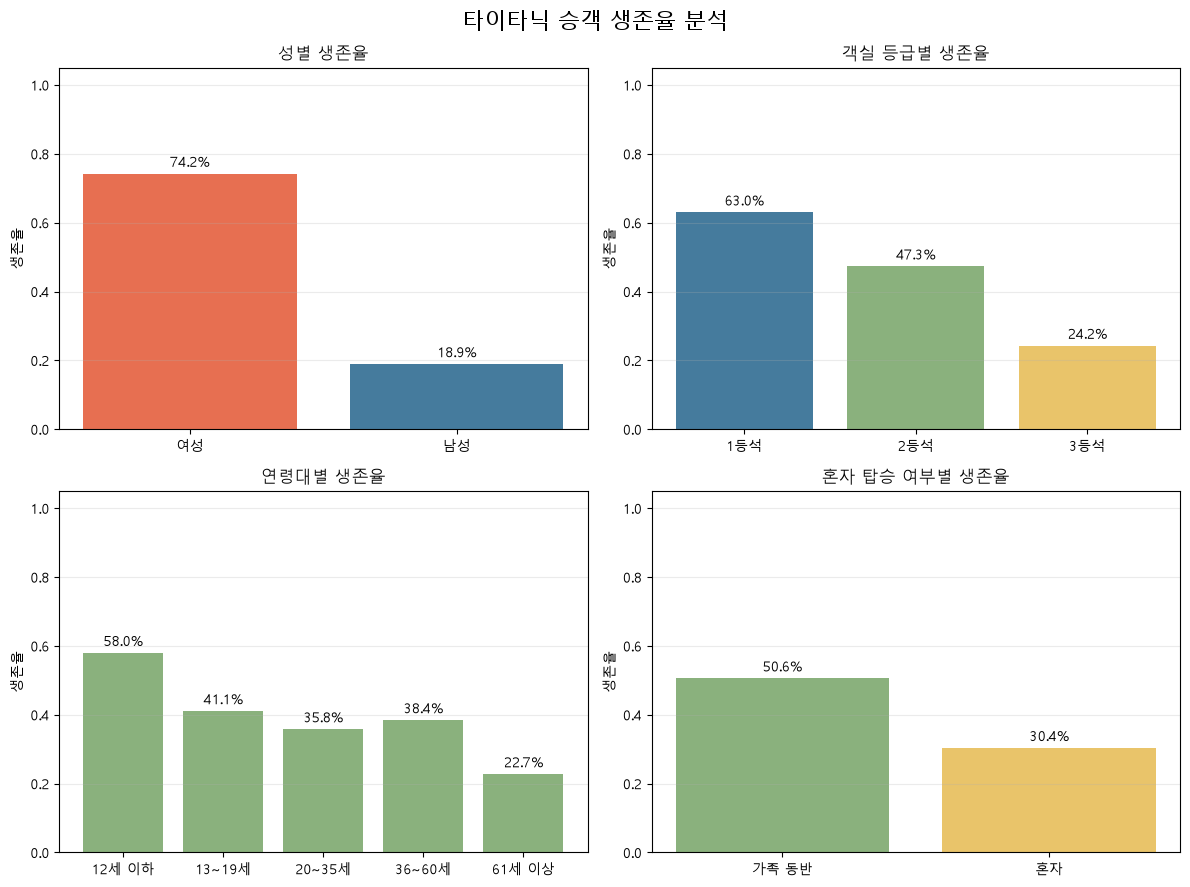

In [5]:
charts = [
    ("sex", ["female", "male"], ["여성", "남성"], "성별 생존율", ["#e76f51", "#457b9d"]),
    ("pclass", [1, 2, 3], ["1등석", "2등석", "3등석"], "객실 등급별 생존율", ["#457b9d", "#8ab17d", "#e9c46a"]),
    ("age_group", ["12세 이하", "13~19세", "20~35세", "36~60세", "61세 이상"], ["12세 이하", "13~19세", "20~35세", "36~60세", "61세 이상"], "연령대별 생존율", ["#8ab17d"] * 5),
    ("alone", [False, True], ["가족 동반", "혼자"], "혼자 탑승 여부별 생존율", ["#8ab17d", "#e9c46a"]),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (column, order, labels, title, colors) in zip(axes.flat, charts):
    rates = df.groupby(column, observed=True)["survived"].mean().reindex(order)
    bars = ax.bar(labels, rates.values, color=colors)
    ax.set_title(title)
    ax.set_ylabel("생존율")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.bar_label(bars, labels=[f"{rate:.1%}" for rate in rates], padding=3)

fig.suptitle("타이타닉 승객 생존율 분석", fontsize=16)
fig.tight_layout()
plt.show()